# P30: repo and docs diet
Regenerates the README figures from `data/` (built by `scripts/line_counts.py` and `scripts/compare_metrics.py`).

In [1]:
import pandas as pd, matplotlib.pyplot as plt, numpy as np
from pathlib import Path
D = Path('data'); F = Path('figures')
docs = pd.read_csv(D/'startup_docs.csv'); areas = pd.read_csv(D/'repo_areas.csv'); eq = pd.read_csv(D/'metrics_equivalence.csv')
C = {'before': '#9aa5b1', 'after': '#2a6f97'}

## Figure 1: start-up docs
Lines every session reads at start-up, before (`d3f73e6`) and after P30.

when,after,before
file,,
CLAUDE.md,242,234
docs/PROJECT_CONTEXT.md,477,679
docs/TASKS.md,930,1374
total,1649,2287


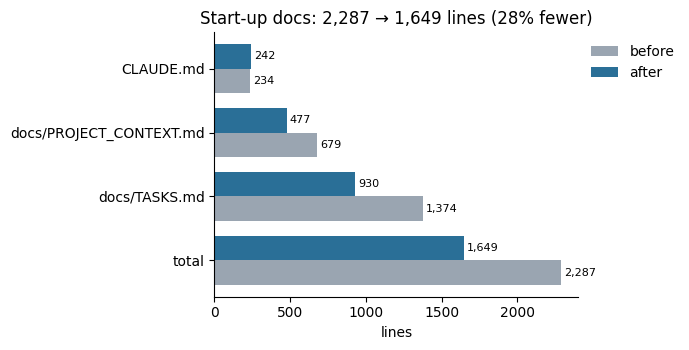

In [2]:
piv = docs.pivot(index='file', columns='when', values='lines').loc[['CLAUDE.md','docs/PROJECT_CONTEXT.md','docs/TASKS.md']]
tot = piv.sum(); piv.loc['total'] = tot
fig, ax = plt.subplots(figsize=(7, 3.6)); y = np.arange(len(piv)); h = 0.38
for i, w in enumerate(['before', 'after']):
    ax.barh(y + (h/2 if w=='before' else -h/2), piv[w], h, color=C[w], label=w)
    for yy, v in zip(y, piv[w]): ax.text(v + 20, yy + (h/2 if w=='before' else -h/2), f'{v:,}', va='center', fontsize=8)
ax.set_yticks(y, piv.index); ax.invert_yaxis(); ax.set_xlabel('lines'); ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1.0, 1.0))
ax.set_title(f"Start-up docs: {tot['before']:,} → {tot['after']:,} lines ({100*(1-tot['after']/tot['before']):.0f}% fewer)")
ax.spines[['top','right']].set_visible(False); fig.tight_layout(); fig.savefig(F/'fig1_startup_docs.png', dpi=150); piv

## Figure 2: repo by area
Text lines in `.py/.md/.txt/.sh` files (left) and tracked bytes incl. baselines (right).

,area,when,files,bytes,text_lines,code_doc_lines
0,claude_files,before,31,691040,15313,15313
1,tools,before,46,397312,8248,8248
2,benchmarks,before,48,12450252,75461,1450
3,docs,before,8,230714,3029,3029
4,claude_files,after,16,468538,9817,9817
5,tools,after,46,397312,8248,8248
6,benchmarks,after,27,6386680,39663,1447
7,docs,after,10,236580,3103,3103


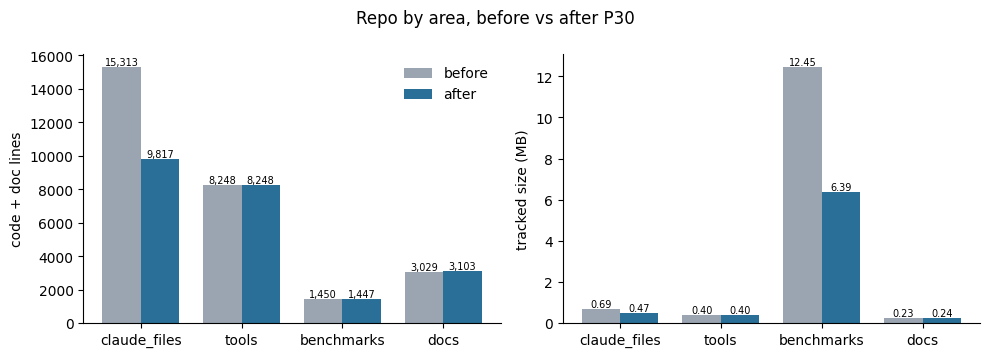

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, col, lab in [(axes[0], 'code_doc_lines', 'code + doc lines'), (axes[1], 'bytes', 'tracked size (MB)')]:
    piv2 = areas.pivot(index='area', columns='when', values=col).loc[['claude_files','tools','benchmarks','docs']]
    if col == 'bytes': piv2 = piv2 / 1e6
    x = np.arange(len(piv2)); w = 0.38
    for i, wh in enumerate(['before', 'after']):
        ax.bar(x + (i - 0.5)*w, piv2[wh], w, color=C[wh], label=wh)
        for xx, v in zip(x, piv2[wh]): ax.text(xx + (i-0.5)*w, v, f'{v:,.0f}' if col!='bytes' else f'{v:.2f}', ha='center', va='bottom', fontsize=7)
    ax.set_xticks(x, piv2.index); ax.set_ylabel(lab); ax.spines[['top','right']].set_visible(False)
axes[0].legend(frameon=False); fig.suptitle('Repo by area, before vs after P30'); fig.tight_layout(); fig.savefig(F/'fig2_repo_areas.png', dpi=150)
areas

## Figure 3: results unchanged
dev_small scorecard `metrics.json`, before vs after, key by key (NaN-aware; `runtime.*` and `config` ignored).

,mode,keys_compared,keys_differing,only_before,only_after
0,assigned,1711,0,0,0
1,full-year,1270,0,0,0


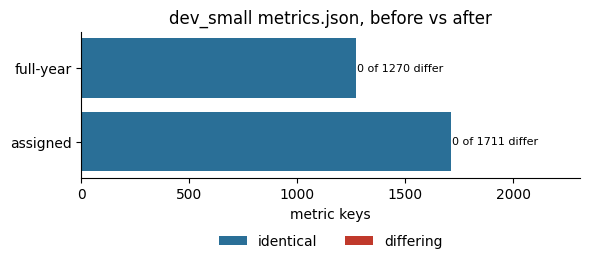

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.0)); y = np.arange(len(eq))
ax.barh(y, eq.keys_compared, color='#2a6f97', label='identical')
ax.barh(y, eq.keys_differing, left=eq.keys_compared - eq.keys_differing, color='#c0392b', label='differing')
for yy, r in zip(y, eq.itertuples()): ax.text(r.keys_compared + 5, yy, f'{r.keys_differing} of {r.keys_compared} differ', va='center', fontsize=8)
ax.set_yticks(y, eq['mode']); ax.set_xlabel('metric keys'); ax.set_xlim(0, eq.keys_compared.max()*1.35)
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=2); ax.spines[['top','right']].set_visible(False); ax.set_title('dev_small metrics.json, before vs after')
fig.tight_layout(); fig.savefig(F/'fig3_metrics_equivalence.png', dpi=150); eq